## Visualizing exchanges with medium

This script corresponds to the modeling of an MCF-7 community in co-culture with Fusobacterium nucleatum. In this part, the objetive was visualizing the community exchanges with the extracellular medium.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import micom

#### Load community

In [8]:
TyF = {'id': ['CanA', 'CanB', 'CanC','Fusobacterium'],
    'file': ["A_1.xml", 'B_1.xml','C_1.xml',"F_1.xml"],
     'abundance': [0.04885,0.1955,0.2265,0.50]
    }

df_TyF = pd.DataFrame(data=TyF)
df_TyF

,id,file,abundance
0,CanA,A_1.xml,0.04885
1,CanB,B_1.xml,0.19550
2,CanC,C_1.xml,0.22650
3,Fusobacterium,F_1.xml,0.50000


In [10]:
TyF = micom.Community (df_TyF, solver = "osqp")
print("build a community with a total of {} reactions.".format(len(TyF.reactions)))

Output()

build a community with a total of 4120 reactions.


In [13]:
TyF.medium =  { #add medium 
'EX_ala_L_m':0.7,
'EX_arg_L_m':0.5,  
'EX_asn_L_m':0.7,
'EX_asp_L_m':0.7,
'EX_ca2_m':0.5,
'EX_chol_m':0.7,
'EX_cl_m':0.5, 
'EX_cobalt2_m':0.5, 
'EX_cu2_m':0.5, 
'EX_cys_L_m':0.7,
'EX_fe2_m':0.5, 
'EX_fe3_m':0.5, 
'EX_gal_m':0.01,  
'EX_gln_L_m':0.7,
'EX_his_L_m':0.7,
'EX_ile_L_m':0.7,
'EX_inost_m':0.7,
'EX_k_m':0.5, 
'EX_leu_L_m':0.7,
'EX_lys_L_m':0.5,  
'EX_met_L_m':0.7,
'EX_mg2_m':0.5,  
'EX_mn2_m':0.5,  
'EX_nac_m':0.5,  
'EX_o2_m':0.7,
'EX_h2o_m':0.7,
'EX_phe_L_m':0.5, 
'EX_pi_m':0.5, 
'EX_pnto_R_m':0.5,
'EX_pro_L_m':0.5, 
'EX_ser_L_m':0.7,
'EX_so4_m':0.5, 
'EX_thr_L_m':0.7,
'EX_trp_L_m':0.5, 
'EX_tyr_L_m':0.5,
'EX_val_L_m':0.5,
'EX_zn2_m':0.5, 
'EX_adocbl_m':0.7,
'EX_anth_m':0.7,
'EX_ascb_L_m':0.7,
'EX_btn_m':0.7,
'EX_fol_m':0.7,
'EX_glc_D_m':0.7,
'EX_glu_L_m':0.7,
'EX_gly_m':0.7,
'EX_gthrd_m':0.7,
'EX_na1_m':0.7,
'EX_ncam_m':0.7,
'EX_pydxn_m':0.7,
'EX_ribflv_m':0.7,
'EX_thm_m':0.7
}

In [12]:
sol_TyF = TyF.cooperative_tradeoff(fraction = 0.6, fluxes =True, pfba = True)
sol_TyF

,abundance,growth_rate,reactions,metabolites
compartments,,,,
CanA,0.050317,0.011182,1126,982
CanB,0.201370,0.044746,742,616
CanC,0.233301,0.051850,1032,807
Fusobacterium,0.515013,0.114466,1029,935
medium,NaN,NaN,191,191


#### Get exchange reactions

In [27]:
fluxes = sol_TyF.fluxes

In [29]:
exchange_cols = fluxes.columns[fluxes.columns.str.startswith("EX_")]

In [30]:
community_exchanges = fluxesTyF[exchange_cols]
community_exchanges_vertical = community_exchanges.reset_index().melt(
    id_vars="compartment", var_name="reaction", value_name="flux"
)
community_exchanges_nz = community_exchanges_vertical[
    community_exchanges_vertical["flux"] != 0
]
community_exchanges_vertical["type"] = community_exchanges_vertical["flux"].apply(
    lambda x: "consumed" if x < 0 else ("secreted" if x > 0 else "no flux")
)

In [63]:
community_exchanges_nz

,compartment,reaction,flux
0,CanA,EX_15dap_e,NaN
1,CanB,EX_15dap_e,NaN
2,CanC,EX_15dap_e,NaN
4,medium,EX_15dap_e,NaN
5,CanA,EX_15dap_m,NaN
...,...,...,...
2455,CanA,EX_zn2_m,NaN
2456,CanB,EX_zn2_m,NaN
2457,CanC,EX_zn2_m,NaN
2458,Fusobacterium,EX_zn2_m,NaN


In [65]:
fluxes = community_exchanges_nz

exchange_fluxes = fluxes[fluxes["reaction"].str.startswith("EX_")]

exchange_fluxes

,compartment,reaction,flux
0,CanA,EX_15dap_e,NaN
1,CanB,EX_15dap_e,NaN
2,CanC,EX_15dap_e,NaN
4,medium,EX_15dap_e,NaN
5,CanA,EX_15dap_m,NaN
...,...,...,...
2455,CanA,EX_zn2_m,NaN
2456,CanB,EX_zn2_m,NaN
2457,CanC,EX_zn2_m,NaN
2458,Fusobacterium,EX_zn2_m,NaN


In [67]:
exchange_total = (
    exchange_fluxes
    .groupby("reaction")["flux"]
    .sum()
    .reset_index()
)

exchange_total

,reaction,flux
0,EX_15dap_e,0.000000
1,EX_15dap_m,0.000000
2,EX_2hb[e],0.000000
3,EX_2hb_e,0.000000
4,EX_2hb_m,0.000000
...,...,...
487,EX_xylt[e],-0.004640
488,EX_xylt_e,-0.004640
489,EX_xylt_m,0.000000
490,EX_zn2_e,-0.000894


#### Get initial medium

In [49]:
initial_medium["metabolite"] = initial_medium["reaction"].str.replace("EX_", "")

In [19]:
initial_medium = pd.DataFrame(
    TyF.medium.items(),
    columns=["reaction", "initial_flux"]
)

initial_medium.head()

,reaction,initial_flux
0,EX_ala_L_m,0.7
1,EX_anth_m,0.7
2,EX_arg_L_m,0.5
3,EX_asn_L_m,0.7
4,EX_asp_L_m,0.7


#### Comparison of initial vs final medium

In [69]:
medium_final = initial_medium.merge(exchange_total, on="reaction", how="outer").fillna(0)

medium_final["final_flux"] = medium_final["initial_flux"] + medium_final["flux"]

medium_final["change"] = medium_final["final_flux"] - medium_final["initial_flux"]

medium_final.sort_values("change", ascending=False).head(20)

,reaction,initial_flux,metabolite,flux,final_flux,change
48,EX_ac_e,0.0,0,6.188380,6.188380,6.188380
155,EX_co2_e,0.0,0,4.861168,4.861168,4.861168
343,EX_nh4_e,0.0,0,4.421370,4.421370,4.421370
49,EX_ac_m,0.0,0,3.187094,3.187094,3.187094
344,EX_nh4_m,0.0,0,2.233708,2.233708,2.233708
156,EX_co2_m,0.0,0,2.225361,2.225361,2.225361
271,EX_h2o[e],0.0,0,2.127914,2.127914,2.127914
236,EX_gly_e,0.0,0,1.050060,1.050060,1.050060
294,EX_indole_e,0.0,0,0.963977,0.963977,0.963977
154,EX_co2[e],0.0,0,0.957201,0.957201,0.957201


In [76]:
medium_final = medium_final[
    medium_final["reaction"].str.endswith("_m")
]
medium_final #filter only the medium reactions

,reaction,initial_flux,metabolite,flux,final_flux,change
1,EX_15dap_m,0.0,0,0.00000,0.00000,0.00000
4,EX_2hb_m,0.0,0,0.00000,0.00000,0.00000
7,EX_2mcit_m,0.0,0,0.00000,0.00000,0.00000
9,EX_2obut_m,0.0,0,0.00000,0.00000,0.00000
13,EX_3aib_D_m,0.0,0,0.00000,0.00000,0.00000
...,...,...,...,...,...,...
480,EX_whhdca_m,0.0,0,0.00000,0.00000,0.00000
483,EX_xmp_m,0.0,0,0.00000,0.00000,0.00000
486,EX_xoltri25_m,0.0,0,0.00000,0.00000,0.00000
489,EX_xylt_m,0.0,0,0.00000,0.00000,0.00000


In [78]:
medium_final["metabolite"] = (
    medium_final["reaction"]
    .str.replace("EX_", "", regex=False)
    .str.replace("_m", "", regex=False)
) #clear the metabolite name

In [ ]:
medium_final.to_csv('initial_vs_final_medium.csv') #save to change the metabolite names
medium_final = pd.read_csv('initial_vs_final_medium.csv', index_col=0)

In [12]:
### load the database in spanish

In [21]:
import chardet

with open('initial_vs_final_medium_espa.csv', 'rb') as f:
    result = chardet.detect(f.read())

print(result)

{'encoding': 'ISO-8859-1', 'confidence': 0.73, 'language': ''}


In [22]:
medium_final_sp = pd.read_csv(
    'initial_vs_final_medium_espa.csv',
    index_col=0,
    encoding=result['encoding']
)

In [23]:
medium_final_sp

,reaction,flujo_inicial,metabolite,flux,flujo_final,change
1,EX_ac_m,0.00,Acetato,3.187094,3.187094,3.187094
2,EX_adocbl_m,0.70,Adenosilcobalamina,0.000000,0.700000,0.000000
3,EX_ala_L_m,0.70,L_Alanina,-0.058492,0.641508,-0.058492
4,EX_anth_m,0.70,Antranilato,0.000000,0.700000,0.000000
5,EX_arg_L_m,0.50,L-Arginina,-0.024778,0.475222,-0.024778
6,EX_asn_L_m,0.70,L-Asparagina,-0.033918,0.666082,-0.033918
7,EX_asp_L_m,0.70,L-Aspartato,-0.700000,0.000000,-0.700000
8,EX_btn_m,0.70,Biotina,0.000000,0.700000,0.000000
9,EX_but_m,0.00,Butirato,0.251581,0.251581,0.251581
10,EX_ca2_m,0.50,Calcio,-0.000460,0.499540,-0.000460


#### Visualizing

In [24]:
# sort by absolute change
top_metabolites = medium_final_sp.reindex(
    medium_final_sp["change"].abs().sort_values(ascending=False).index
).head(30)

top_metabolites

,reaction,flujo_inicial,metabolite,flux,flujo_final,change
1,EX_ac_m,0.0,Acetato,3.187094,3.187094,3.187094
39,EX_nh4_m,0.0,Amonio,2.233708,2.233708,2.233708
14,EX_co2_m,0.0,Dióxido de carbono,2.225361,2.225361,2.225361
7,EX_asp_L_m,0.7,L-Aspartato,-0.700000,0.000000,-0.700000
48,EX_ser_L_m,0.7,L-Serina,-0.700000,0.000000,-0.700000
52,EX_thr_L_m,0.7,L-Treonina,-0.700000,0.000000,-0.700000
40,EX_o2_m,0.7,Oxígeno,-0.700000,0.000000,-0.700000
25,EX_gly_m,0.7,Glicina,0.555560,1.255560,0.555560
53,EX_trp_L_m,0.5,L-Triptófano,-0.500000,0.000000,-0.500000
28,EX_indole_m,0.0,Indol,0.496460,0.496460,0.496460


In [25]:
heatmap_data = top_metabolites.set_index("metabolite")[["flujo_inicial", "flujo_final"]]

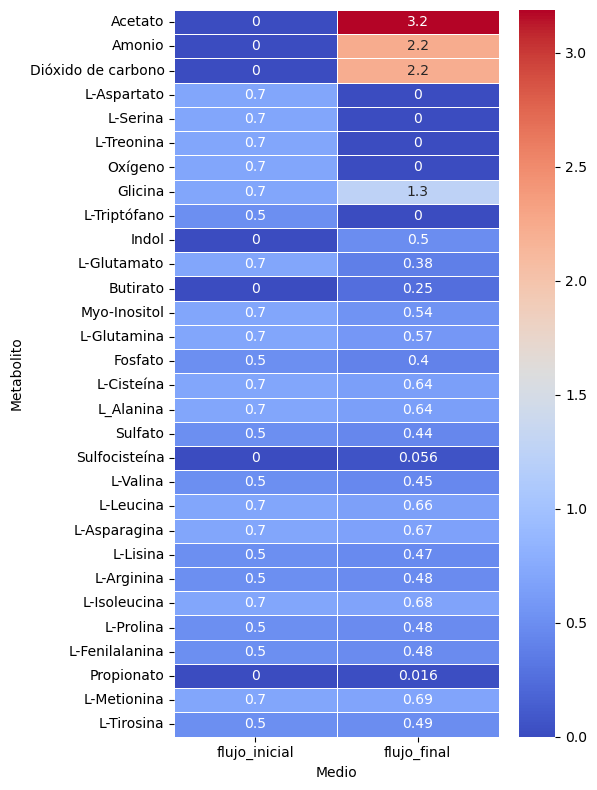

In [26]:
plt.figure(figsize=(6,8))

sns.heatmap(
    heatmap_data,
    cmap="coolwarm",
    annot=True,
    linewidths=0.5
)
plt.ylabel("Metabolito")
plt.xlabel("Medio")
plt.tight_layout()
plt.savefig("plots/initial_vs_final_medium_ESPAÑOL.png", dpi=300, bbox_inches="tight")
plt.show()